# NB03: Real Coupling and Validation

This notebook calls the RELIC coupling and validation components directly.
You will learn:

1. How `TimeStagger` negotiates a common coupling step for external component clocks
2. How `CouplingCapabilityRegistry` reports implemented and not-implemented coupling features and the coupling operator types
3. How `HealthChecker` reports the status of each RELIC subsystem
4. How the conservation ledger lists the member variables of each conserved quantity, how the domain budget residual is defined, and which invariant contracts the test suite checks

Dependency edges between Functors and the topological execution order are
shown in NB10. NB11 covers the incidence matrix, budget residuals and
invariant drift in more depth.

**Prerequisites:** NB01, NB02.

**Theory Reference:** `docs/source/coertheory.md`, Section 2.2 (Theorem 3.1,
structural conservation), Section 3.3 (conservation ledger and domain budget
residuals) and Theorem 3.6.6 (transactional state update).

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below call real RELIC objects: the coupling clock protocol, the coupling capability registry, the subsystem health checker and the conservation ledger. The notebook defines no process equations of its own.


### Coupling and Conservation Laws

Coupled components exchange fluxes through shared state variables. RELIC
checks conservation at run time with a **domain budget residual**
(`docs/source/coertheory.md`, Section 3.3). For a conservation domain $D$
(for example `carbon.total`), whose member variables are the members of the
`ContractRegistry` domain $D$ (`get_domain_members(D)`):

$$
r_D = \left|\,\Delta S_D - \left(\sum F_{\text{in}} - \sum F_{\text{out}}\right) \Delta t\,\right|
$$

where $\Delta S_D$ is the summed storage change of the member variables over
the step, $F_{\text{in}}$ and $F_{\text{out}}$ are the boundary flux rates into
and out of the domain, and $\Delta t$ is the step length.
`ConservationGuardian.check_domain()` (`relic/validation/conservation_guardian.py`)
passes the check when

$$
r_D \le a_{\text{tol}} + r_{\text{tol}} \left|\left(\sum F_{\text{in}} - \sum F_{\text{out}}\right)\Delta t\right|
$$

A failed check is logged as an error; `check_domain()` does not raise. The
StateManager conservation checks (`relic/core/state/conservation.py`) call it
with a StateManager conservation tolerance as $a_{\text{tol}}$ and
$r_{\text{tol}} = 0$. `check_domain()` takes the member list from the
`ContractRegistry` it was built with, not from the StateManager conservation
ledger; for the packaged contracts the two lists hold the same variables
(see the conservation ledger section below).

**Theorem 3.1** (Structural Conservation, `coertheory.md` Section 2.2) is a
separate structural statement. If the stocks $u$ obey
$du/dt = \mathbf{B} f(u)$ for a physical exchange incidence matrix
$\mathbf{B} \in \{-1, 0, +1\}^{n \times m}$, then $c^\top u$ is constant for
every $c \in \ker(\mathbf{B}^\top)$. The incidence matrix of the execution
dependency graph does not by itself prove mass, energy or element
conservation.

## Setup and Imports

We set up the project path, import `TimeStagger`, `ClockConfig`, `TimeUnit`,
`CouplingCapabilityRegistry` and `HealthChecker`, and create the output folder
`tutorial/primary/output`.

In [1]:
from __future__ import annotations

import asyncio

# --- Environment Guard (prevent OpenMP duplicate lib crash) ---
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

import json
from pathlib import Path

DEFAULT_PROJECT_ROOT = Path(os.environ.get("RELIC_PROJECT_ROOT", os.getcwd()))

def locate_project_root() -> Path:
    candidates = [
        Path.cwd().resolve(),
        *Path.cwd().resolve().parents,
        DEFAULT_PROJECT_ROOT,
    ]
    for candidate in candidates:
        candidate = candidate.resolve()
        if (candidate / "relic").is_dir() and (candidate / "docs" / "source" / "architecture_overview.md").is_file():
            return candidate
    raise FileNotFoundError("Project root not found. Set RELIC_PROJECT_ROOT if needed.")

PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from relic.coupling.protocol.time_stagger import ClockConfig, TimeStagger, TimeUnit
from relic.coupling.capability_registry import CouplingCapabilityRegistry
from relic.validation.healthcheck import HealthChecker

OUTPUT_DIR = PROJECT_ROOT / "tutorial" / "primary" / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("[OK] project_root =", PROJECT_ROOT)
print("[OK] output_dir =", OUTPUT_DIR)

[OK] project_root = <RELIC_ROOT>
[OK] output_dir = tutorial\primary\output


## Clock Negotiation Between Coupled Components

`TimeStagger` (`relic/coupling/protocol/time_stagger.py`) negotiates a common
coupling step for external components with NUOPC-style clocks. It is not the
scheduler of `RELICSimulator`: Functors inside the simulator run in the
fast/medium/slow execution groups (`relic/core/simulator/time_ops.py`,
`execution_loop.py`).

The cell registers three clocks (land 30 min, atmosphere 1 h, hydrology 2 h)
and negotiates with the `min`, `gcd` and `lcm` strategies.
`get_subcycle_ratio()` compares each clock with the most recently negotiated
step, which is the LCM here, so each ratio is the number of component steps
per coupling step. `shift(t)` returns `t + lead_seconds - lag_seconds`.

The output shows min = gcd = 1800 s, lcm = 7200 s, ratios land 4,
atmosphere 2, hydrology 1, `shift(7200) = 6960` s (lag 300 s, lead 60 s) and
no consistency warnings.

In [2]:
# References:
# - Balaji et al. (2006) coupling interval effects in coupled models.
# - ESMF and NUOPC clock negotiation concepts for component synchronization.
# - relic/coupling/protocol/time_stagger.py (TimeStagger, ClockConfig).
# Mathematical expression:
# - dt_common_min = min(dt_1, dt_2, ..., dt_n)
# - dt_common_gcd = GCD(dt_1, dt_2, ..., dt_n), on integer milliseconds int(dt_i * 1000)
# - dt_common_lcm = LCM(dt_1, dt_2, ..., dt_n), on integer milliseconds int(dt_i * 1000)
# - ratio_i = max(dt_i, dt_neg) / min(dt_i, dt_neg)
# - shift(t) = t + lead_seconds - lag_seconds
# Parameter meanings:
# - dt_i: time step of component i.
# - dt_common_*: negotiated common time step for each strategy.
# - dt_neg: common step of the most recent negotiate() call (the LCM in this cell).
# - ratio_i: integer alignment ratio of component i against dt_neg.
# - lag_seconds: lag for imported timestamps; lead_seconds: lead for exported timestamps.
# - t: timestamp passed to shift().
# Units:
# - dt_i, dt_common_*, dt_neg, lag_seconds, lead_seconds, t: s
#   (ClockConfig.to_seconds converts minutes, hours and days to seconds).
# - ratio_i: dimensionless integer.
# Domain/constraints:
# - Every dt_i must be > 0; negotiate() raises ClockSyncError otherwise.
# - ratio_i must be an integer within 0.01; get_subcycle_ratio() raises ClockSyncError otherwise.
# - validate_temporal_consistency() returns warnings instead of raising.
# Sign convention:
# - shift() adds lead_seconds and subtracts lag_seconds; with lag 300 s and
#   lead 60 s a timestamp moves 240 s earlier.

time_stagger = TimeStagger(lag_seconds=300.0, lead_seconds=60.0)
time_stagger.register_clock("land", ClockConfig(time_step=30.0, unit=TimeUnit.MINUTES))
time_stagger.register_clock("atmosphere", ClockConfig(time_step=1.0, unit=TimeUnit.HOURS))
time_stagger.register_clock("hydrology", ClockConfig(time_step=2.0, unit=TimeUnit.HOURS))

negotiated_min = time_stagger.negotiate("min")
negotiated_gcd = time_stagger.negotiate("gcd")
negotiated_lcm = time_stagger.negotiate("lcm")

subcycle_ratios = {
    "land": time_stagger.get_subcycle_ratio("land"),
    "atmosphere": time_stagger.get_subcycle_ratio("atmosphere"),
    "hydrology": time_stagger.get_subcycle_ratio("hydrology"),
}
consistency_warnings = time_stagger.validate_temporal_consistency()
shifted_timestamp = time_stagger.shift(7200.0)

time_stagger_summary = {
    "negotiated_min_seconds": negotiated_min,
    "negotiated_gcd_seconds": negotiated_gcd,
    "negotiated_lcm_seconds": negotiated_lcm,
    "subcycle_ratios": subcycle_ratios,
    "shifted_timestamp_from_7200": shifted_timestamp,
    "warnings": consistency_warnings,
}

time_stagger_summary

{'negotiated_min_seconds': 1800.0,
 'negotiated_gcd_seconds': 1800.0,
 'negotiated_lcm_seconds': 7200.0,
 'subcycle_ratios': {'land': 4, 'atmosphere': 2, 'hydrology': 1},
 'shifted_timestamp_from_7200': 6960.0,
 'warnings': []}

## Coupling Capability Registry

`CouplingCapabilityRegistry` (`relic/coupling/capability_registry.py`)
declares each coupling feature with a status (`implemented`, `partial` or
`not_implemented`), its limitations, alternatives and error code. A
ParameterManager switch `coupling.capabilities.<feature>.enabled: false`
downgrades a declared feature to `not_implemented`. Importing `relic.coupling`
registers the `external_coupling_runtime` entry as implemented after its
`external` subpackage has been imported. The registry also maps coupling
operator names to their classes.

The output shows 10 implemented features, no partial ones and one
not-implemented feature, `conservative_regridding_irregular`, whose declared
status is `not_implemented` and whose error code is `COUPLING_E1001`. The
four operator types are `conservation_fixer`, `temporal_lag`,
`constraint_projector` and `flux_kernel`.

In [3]:
capability_status = CouplingCapabilityRegistry.get_implementation_status()
irregular_feature = CouplingCapabilityRegistry.get_capability("conservative_regridding_irregular")
if irregular_feature is None:
    raise KeyError("conservative_regridding_irregular is not declared in CouplingCapabilityRegistry")
operator_names = CouplingCapabilityRegistry.list_coupling_operator_types()
operator_class_names = {
    name: CouplingCapabilityRegistry.get_coupling_operator_type(name).__name__
    for name in operator_names
}

# get_implementation_status() always returns the keys implemented, partial and not_implemented.
capability_summary = {
    "implemented_features": capability_status["implemented"],
    "partial_features": capability_status["partial"],
    "not_implemented_features": capability_status["not_implemented"],
    "regular_grid_bilinear_implemented": CouplingCapabilityRegistry.is_implemented("regular_grid_bilinear"),
    "irregular_feature_error_code": CouplingCapabilityRegistry.get_error_code("conservative_regridding_irregular"),
    "irregular_feature_alternatives": CouplingCapabilityRegistry.get_alternatives("conservative_regridding_irregular"),
    "irregular_feature_status": irregular_feature.status,
    "operator_names": operator_names,
    "operator_class_names": operator_class_names,
}

{
    "implemented_count": len(capability_summary["implemented_features"]),
    "partial_count": len(capability_summary["partial_features"]),
    "not_implemented_count": len(capability_summary["not_implemented_features"]),
    "not_implemented_features": capability_summary["not_implemented_features"],
    "irregular_feature_status": capability_summary["irregular_feature_status"],
    "irregular_feature_error_code": capability_summary["irregular_feature_error_code"],
    "operator_names": capability_summary["operator_names"],
}

{'implemented_count': 10,
 'partial_count': 0,
 'not_implemented_count': 1,
 'not_implemented_features': ['conservative_regridding_irregular'],
 'irregular_feature_status': 'not_implemented',
 'irregular_feature_error_code': 'COUPLING_E1001',
 'operator_names': ['conservation_fixer',
  'temporal_lag',
  'constraint_projector',
  'flux_kernel']}

## Subsystem Health Check

`HealthChecker.check_all()` (`relic/validation/healthcheck.py`) runs one check
per subsystem (compute, data, params, optimize, stochastic, config,
orchestration) and maps each result to `HEALTHY`, `DEGRADED`, `UNHEALTHY` or
`UNAVAILABLE`. The overall status is `UNHEALTHY` when any subsystem is
`UNHEALTHY` or `UNAVAILABLE`, otherwise `DEGRADED` when any subsystem is
`DEGRADED`.

The output shows an overall `DEGRADED` status. `optimize` is `DEGRADED`
because the optimize check has no runtime-ready path:
`_check_optimize_health()` always sets `runtime_ready = False` and an empty
`ready_optimizers` list, and it reports `DEGRADED` whenever at least one
component is available or listed as unclassified, so this subsystem cannot
be `HEALTHY`. The component declarations only decide the list in which each
component is reported: all four components (calibration, assimilation,
sensitivity, uncertainty) declare `runtime_ready: False` with the contract
`algorithm_component_only` (`relic/optimization/__init__.py`) and are listed
as `blocked_optimizers`.
`stochastic` is `DEGRADED` because `WeatherGenerator` is declared not
runtime-ready and `EnsembleRunner` declares no runtime readiness
(`unclassified_samplers`). The other five subsystems are `HEALTHY` and no
errors are reported.

The cell reports the warnings and errors of the current health checker.
Importing `relic.scientific` fills its registry without configuring logging
and excludes `*_cli.py` modules. CLI root logging belongs to the entry point,
not package import.

In [4]:
health_checker = HealthChecker({})
health_payload = health_checker.check_all(detailed=False, benchmark=False)
subsystem_statuses = {
    name: entry["status"]
    for name, entry in health_payload["subsystems"].items()
}

health_summary = {
    "overall_status": health_payload["overall_status"],
    "subsystem_statuses": subsystem_statuses,
    "optimize_runtime": health_payload["subsystems"]["optimize"]["runtime"],
    "stochastic_runtime": health_payload["subsystems"]["stochastic"]["runtime"],
    "warnings": health_payload["warnings"],
    "errors": health_payload["errors"],
    "recommendations": health_payload["recommendations"],
}

health_summary

Configuration loaded with 1 warnings


{'overall_status': 'DEGRADED',
 'subsystem_statuses': {'compute': 'HEALTHY',
  'data': 'HEALTHY',
  'params': 'HEALTHY',
  'optimize': 'DEGRADED',
  'stochastic': 'DEGRADED',
  'config': 'HEALTHY',
  'orchestration': 'HEALTHY'},
 'optimize_runtime': {'status': '[N]',
  'ready': False,
  'ready_optimizers': [],
  'blocked_optimizers': ['calibration',
   'assimilation',
   'sensitivity',
   'uncertainty'],
  'unclassified_optimizers': []},
 'stochastic_runtime': {'status': '[N]',
  'ready': False,
  'ready_samplers': ['EulerMaruyamaSolver', 'GillespieSSA'],
  'blocked_samplers': ['WeatherGenerator'],
  'unclassified_samplers': ['EnsembleRunner']},
 'warnings': ['Some optimization components are not production-runtime-ready',
  'Some stochastic samplers are not production-runtime-ready'],
 'errors': [],
 'recommendations': ['Review warnings in optimize subsystem',
  'Review warnings in stochastic subsystem']}

In [5]:
summary = {
    "time_stagger": time_stagger_summary,
    "capability_registry": capability_summary,
    "healthcheck": health_summary,
}

assert summary["time_stagger"]["negotiated_min_seconds"] == 1800.0
assert summary["time_stagger"]["negotiated_gcd_seconds"] == 1800.0
assert summary["time_stagger"]["negotiated_lcm_seconds"] == 7200.0
assert summary["time_stagger"]["subcycle_ratios"]["land"] == 4
assert summary["time_stagger"]["subcycle_ratios"]["atmosphere"] == 2
assert summary["time_stagger"]["subcycle_ratios"]["hydrology"] == 1
assert summary["time_stagger"]["shifted_timestamp_from_7200"] == 6960.0
assert summary["capability_registry"]["regular_grid_bilinear_implemented"] is True
assert summary["capability_registry"]["irregular_feature_error_code"] == "COUPLING_E1001"
assert "temporal_lag" in summary["capability_registry"]["operator_names"]
assert summary["healthcheck"]["overall_status"] in {"HEALTHY", "DEGRADED"}
assert "compute" in summary["healthcheck"]["subsystem_statuses"]
assert "orchestration" in summary["healthcheck"]["subsystem_statuses"]

output_path = OUTPUT_DIR / "coupling_and_validation_summary.json"
output_path.write_text(json.dumps(summary, indent=2, ensure_ascii=True), encoding="utf-8")

print("[OK] wrote", output_path)
print("[OK] health_overall =", summary["healthcheck"]["overall_status"])
print("[OK] negotiated_lcm_seconds =", summary["time_stagger"]["negotiated_lcm_seconds"])
print("[OK] irregular_feature_error_code =", summary["capability_registry"]["irregular_feature_error_code"])

[OK] wrote tutorial\primary\output\coupling_and_validation_summary.json
[OK] health_overall = DEGRADED
[OK] negotiated_lcm_seconds = 7200.0
[OK] irregular_feature_error_code = COUPLING_E1001


## Conservation Ledger

`relic.core.conservation_registry` assembles the element ledger that tells the
conservation checks which state variables belong to each conserved quantity.
It exports three functions:

- `load_parameter_ledger()` reads the variable lists under
  `validation.conservation.ledger` from the parameter database.
- `build_conservation_ledger(contract_registry)` merges every domain of a
  `ContractRegistry` with that parameter ledger. Each domain is keyed by the
  lower-cased part of its name before the first dot, so `carbon.total`
  becomes `carbon`.
- `merge_ledgers(*ledgers)` is the order-preserving union without duplicates
  used for that merge.

A `ContractRegistry` seeds one `<element>.total` domain per parameter-ledger
element when it is constructed and adds every variable whose SCM contract
declares `accumulates: <domain>` to that domain. The ledger holds variable
names only. It has no weights, tolerances or Functor lists: the conservation tolerances
live in `relic/parameters/database/relic/validation/conservation.yaml`, and
Functor-level conservation claims are excluded on purpose. The StateManager
and the simulator build their ledger with `build_conservation_ledger()`
(`initialize_default_conservation_ledger`, `refresh_conservation_ledger`).

The cell below loads the packaged contracts with `load_contract_registry()`,
prints the registry domains and then prints, for each element, the number of
members of the `<element>.total` registry domain, the number of
parameter-ledger members and the size of the merged ledger. The packaged
registry declares `carbon.total`, `nitrogen.total`, `phosphorus.total` and
`water.total`. The cell prints current counts and checks membership inclusion;
registry domains already contain their parameter-ledger variables.

In [6]:
# References:
# - relic/core/conservation_registry.py (build_conservation_ledger, load_parameter_ledger, merge_ledgers)
# - relic/contracts/contract_loader.py (ContractRegistry conservation domains)
# - docs/source/coertheory.md Section 3.3 (conservation ledger and domain budget residuals)
# Mathematical expression:
#   M_registry(d) = merge(S(d), {v : contract(v).accumulates = d}),
#     with S(e.total) = M_parameter(e) and S(d) = {} for any other domain d
#   L(e) = merge(M_registry(d_1), ..., M_registry(d_k), M_parameter(e)),
#     over the registry domains d_j with prefix(d_j) = e, in list_domains() order
#   merge = ordered union without duplicates (merge_ledgers)
# Parameter meanings:
#   e: conserved element or quantity (carbon, nitrogen, phosphorus, water).
#   d: ContractRegistry domain name; prefix(d) is its lower-cased part before the
#     first dot. The packaged registry has only carbon.total, nitrogen.total,
#     phosphorus.total and water.total.
#   M_parameter(e): variable names listed under validation.conservation.ledger.e.
#   M_registry(d): members of ContractRegistry domain d; e.total is seeded from
#     M_parameter(e) at construction, and every variable whose SCM contract declares
#     accumulates: d is added to d.
#   L(e): merged ledger used by the StateManager conservation checks.
# Units:
#   The ledger holds variable names only; each variable's units come from its contract.
# Domain/constraints:
#   load_parameter_ledger() raises RuntimeError when no ParameterManager is
#   available, KeyError when the validation.conservation.ledger namespace has no
#   entries (missing or empty namespace) and ValueError when the namespace has
#   entries but none of them is a list or tuple holding at least one string.
#   load_contract_registry() raises FileNotFoundError on a missing contract
#   directory and ValueError on an unreadable, schema-invalid or duplicate contract.
# Sign convention:
#   Not applicable: the ledger defines membership only; no fluxes are computed here.

import inspect

import relic.core.conservation_registry as conservation_registry
from relic.contracts import load_contract_registry

print("conservation_registry exports:", conservation_registry.__all__)
for name in conservation_registry.__all__:
    print(f"  {name}{inspect.signature(getattr(conservation_registry, name))}")

contract_registry = load_contract_registry()
parameter_ledger = conservation_registry.load_parameter_ledger()
canonical_ledger = conservation_registry.build_conservation_ledger(contract_registry)

print()
print("registry domains:", contract_registry.list_domains())
print(f"{'element':<12}{'registry':>10}{'parameter':>11}{'merged':>8}  first merged members")
for element in sorted(canonical_ledger):
    registry_members = contract_registry.get_domain_members(f"{element}.total")
    parameter_members = parameter_ledger[element] if element in parameter_ledger else []
    merged_members = canonical_ledger[element]
    assert set(registry_members) <= set(merged_members)
    assert set(parameter_members) <= set(merged_members)
    print(
        f"{element:<12}{len(registry_members):>10}{len(parameter_members):>11}"
        f"{len(merged_members):>8}  {merged_members[:4]}"
    )

conservation_registry exports: ['build_conservation_ledger', 'load_parameter_ledger', 'merge_ledgers']
  build_conservation_ledger(contract_registry: 'Any' = None, *, force_reload: 'bool' = False) -> 'Dict[str, List[str]]'
  load_parameter_ledger(force_reload: 'bool' = False) -> 'Dict[str, List[str]]'
  merge_ledgers(*ledgers: 'Dict[str, List[str]]') -> 'Dict[str, List[str]]'

registry domains: ['carbon.total', 'nitrogen.total', 'phosphorus.total', 'water.total']
element       registry  parameter  merged  first merged members
carbon              54         19      54  ['biosphere.leaf_carbon', 'leaf_carbon', 'biosphere.root_carbon', 'root_carbon']
nitrogen            32         11      32  ['biosphere.plant_nitrogen', 'plant_nitrogen', 'pedosphere.soil_nitrogen', 'soil_nitrogen']
phosphorus           7          4       7  ['pedosphere.soil_phosphorus', 'soil_phosphorus', 'biosphere.plant_phosphorus', 'plant_phosphorus']
water                8          8       8  ['hydrosphere.soil_wate

## Invariant Contracts (I1-I7)

The test suite in `test/invariants/` checks seven invariant contracts. They
test the StateManager update semantics, the `UnitConverter` and the
conservation diagnostics of the anthroposphere management Functors; they are
test-suite checks, not checks that run on each Functor during a simulation.

| ID | Name | What the test checks |
|----|------|----------------------|
| I1 | No Side Effects | `StateManager.get_state()` and building an `UpdateItem` leave the state unchanged (`side_effects.test.py`) |
| I2 | Unit Consistency | `UnitConverter` round trips return the input value and linear conversions keep the order of values (`units.test.py`) |
| I3 | Conservation | A closed transfer between two conserved pools has zero net change, $\Delta A + \Delta B = 0$; the management Functors emit conservation diagnostics (`conservation.test.py`) |
| I4 | Reversibility | $+\Delta$ then $-\Delta$ with `ACCUMULATE` restores the initial state (`reversibility.test.py`) |
| I5 | Commutativity | Independent `ACCUMULATE` increments give the same state in either order (`commutativity.test.py`) |
| I6 | dt-Scaling | `per_second` increments scale linearly with $\Delta t$, `per_step` increments do not depend on $\Delta t$, and two split steps equal one whole step (`dt_scaling.test.py`) |
| I7 | Bounds Clipping | Clipping to a declared bound sets the state to the bound and records the diagnostic `clip_loss` $= (S + \Delta) - \text{bound}$; the conservation report stays free of violations when the applied change is routed to a declared loss pool (`bounds_clipping.test.py`) |

A failing invariant test points to a defect in these core update paths, not
to a configuration error.

---
## Visualization: Coupling Validation Results

The figure plots the values collected above: (a) the negotiated coupling
steps, (b) the subcycle ratios against the LCM step, (c) the number of
capability-registry features per status and (d) the health status of each
subsystem.


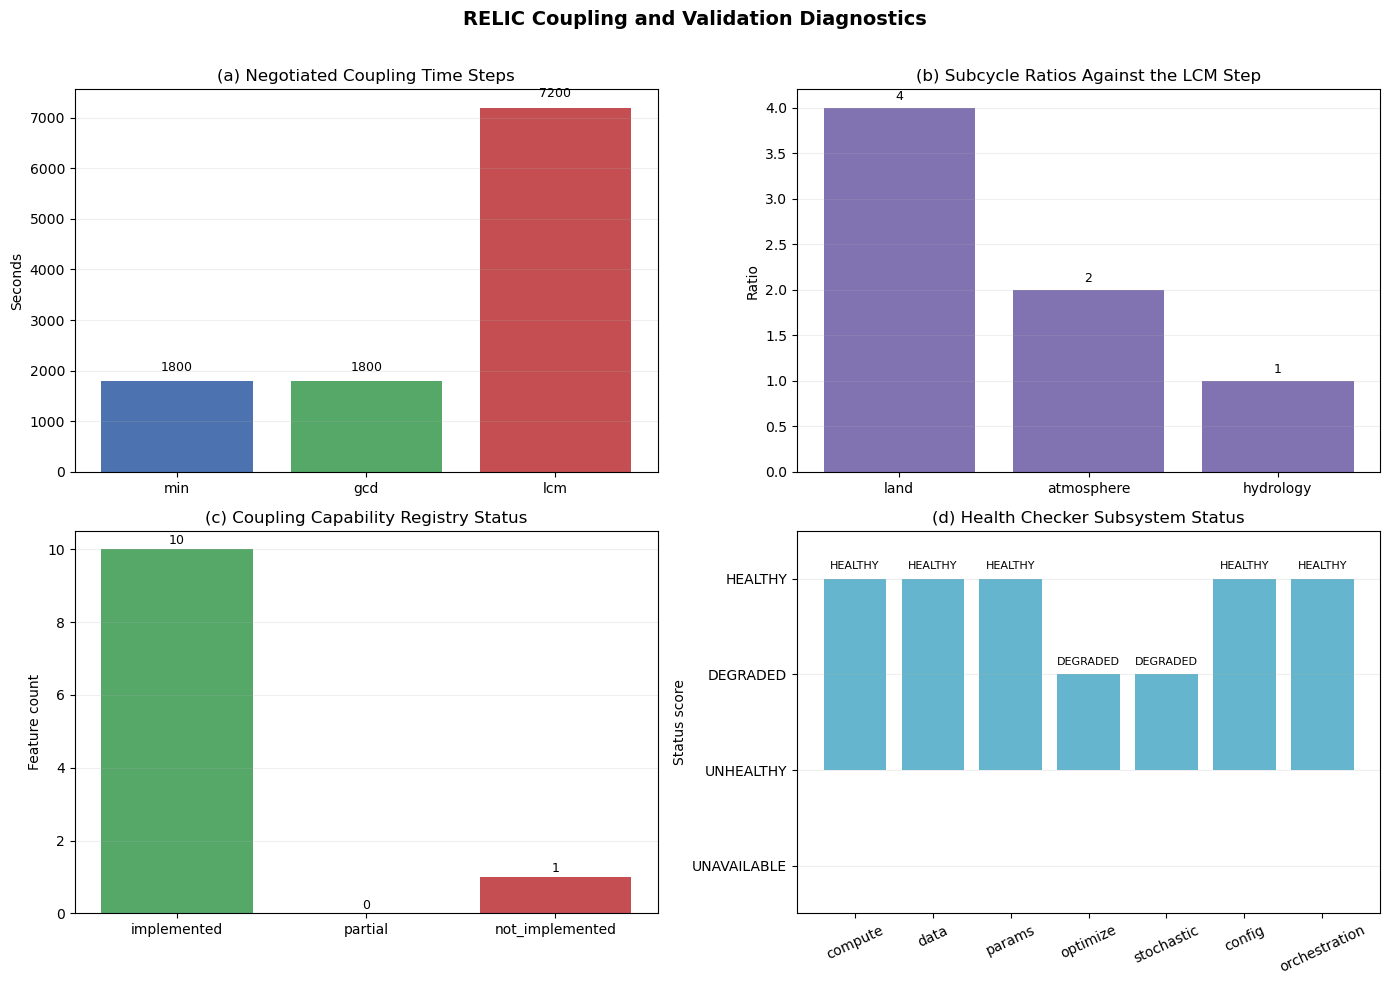

In [7]:
# References:
# - Balaji et al. (2006) coupling interval effects in coupled models.
# - ESMF and NUOPC clock negotiation concepts for component synchronization.
# - relic.coupling.protocol.time_stagger, relic.coupling.capability_registry
#   and relic.validation.healthcheck.
# Mathematical expression:
# - dt_common in {min(dt_i), gcd(dt_i), lcm(dt_i)}
# - ratio_i = max(dt_i, dt_neg) / min(dt_i, dt_neg), dt_neg = LCM step (last negotiation)
# - capability_count_k = |{feature_j : status_j = k}|
# - score(status): HEALTHY = 2, DEGRADED = 1, UNHEALTHY = 0, UNAVAILABLE = -1
# Parameter meanings:
# - dt_i: component time step; dt_common: negotiated common step.
# - ratio_i: subcycle ratio of component i against the LCM step.
# - capability_count_k: number of coupling features with status k.
# - score: plot position of a subsystem status (visualization only).
# Units:
# - dt_i, dt_common, dt_neg: s; ratio_i, capability_count_k, score: dimensionless.
# Domain/constraints:
# - All dt_i > 0 and ratio_i is an integer >= 1 (TimeStagger raises otherwise).
# - HealthChecker returns only the four statuses above; any other status raises KeyError here.
# Sign convention:
# - Not applicable: no fluxes are plotted.

import torch
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline

negotiated_seconds = torch.tensor([
    float(summary["time_stagger"]["negotiated_min_seconds"]),
    float(summary["time_stagger"]["negotiated_gcd_seconds"]),
    float(summary["time_stagger"]["negotiated_lcm_seconds"]),
], dtype=torch.float64)
negotiated_labels = ["min", "gcd", "lcm"]

subcycle_labels = list(summary["time_stagger"]["subcycle_ratios"].keys())
subcycle_values = torch.tensor(
    [float(summary["time_stagger"]["subcycle_ratios"][name]) for name in subcycle_labels],
    dtype=torch.float64,
)

capability_labels = ["implemented", "partial", "not_implemented"]
capability_values = torch.tensor([
    float(len(summary["capability_registry"]["implemented_features"])),
    float(len(summary["capability_registry"]["partial_features"])),
    float(len(summary["capability_registry"]["not_implemented_features"])),
], dtype=torch.float64)

status_to_score = {"HEALTHY": 2.0, "DEGRADED": 1.0, "UNHEALTHY": 0.0, "UNAVAILABLE": -1.0}
subsystem_labels = list(summary["healthcheck"]["subsystem_statuses"].keys())
subsystem_scores = torch.tensor([
    status_to_score[summary["healthcheck"]["subsystem_statuses"][name]]
    for name in subsystem_labels
], dtype=torch.float64)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].bar(negotiated_labels, negotiated_seconds.tolist(), color=["#4C72B0", "#55A868", "#C44E52"])
axes[0, 0].set_ylabel("Seconds")
axes[0, 0].set_title("(a) Negotiated Coupling Time Steps")
axes[0, 0].grid(True, axis="y", alpha=0.2)
for idx, value in enumerate(negotiated_seconds.tolist()):
    axes[0, 0].text(idx, value + max(negotiated_seconds.tolist()) * 0.02, f"{value:.0f}", ha="center", va="bottom", fontsize=9)

axes[0, 1].bar(subcycle_labels, subcycle_values.tolist(), color="#8172B2")
axes[0, 1].set_ylabel("Ratio")
axes[0, 1].set_title("(b) Subcycle Ratios Against the LCM Step")
axes[0, 1].grid(True, axis="y", alpha=0.2)
for idx, value in enumerate(subcycle_values.tolist()):
    axes[0, 1].text(idx, value + 0.05, f"{value:.0f}", ha="center", va="bottom", fontsize=9)

axes[1, 0].bar(capability_labels, capability_values.tolist(), color=["#55A868", "#CCB974", "#C44E52"])
axes[1, 0].set_ylabel("Feature count")
axes[1, 0].set_title("(c) Coupling Capability Registry Status")
axes[1, 0].grid(True, axis="y", alpha=0.2)
for idx, value in enumerate(capability_values.tolist()):
    axes[1, 0].text(idx, value + 0.05, f"{value:.0f}", ha="center", va="bottom", fontsize=9)

axes[1, 1].bar(subsystem_labels, subsystem_scores.tolist(), color="#64B5CD")
axes[1, 1].set_ylabel("Status score")
axes[1, 1].set_title("(d) Health Checker Subsystem Status")
axes[1, 1].set_ylim(-1.5, 2.5)
axes[1, 1].set_yticks([-1.0, 0.0, 1.0, 2.0])
axes[1, 1].set_yticklabels(["UNAVAILABLE", "UNHEALTHY", "DEGRADED", "HEALTHY"])
axes[1, 1].tick_params(axis="x", rotation=25)
axes[1, 1].grid(True, axis="y", alpha=0.2)
for idx, name in enumerate(subsystem_labels):
    status_name = summary["healthcheck"]["subsystem_statuses"][name]
    axes[1, 1].text(idx, subsystem_scores.tolist()[idx] + 0.08, status_name, ha="center", va="bottom", fontsize=8)

plt.suptitle("RELIC Coupling and Validation Diagnostics", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0.0, 0.0, 1.0, 0.97])
display(plt.gcf())
plt.close(plt.gcf())


## Summary

This notebook called the RELIC coupling and validation components:
- `TimeStagger` negotiated a 1800 s (min, gcd) or 7200 s (lcm) coupling step for three external clocks, with subcycle ratios 4, 2 and 1 against the LCM step
- `CouplingCapabilityRegistry` listed 10 implemented features, no partial ones and one not-implemented feature (`conservative_regridding_irregular`, `COUPLING_E1001`) plus four coupling operator types
- `HealthChecker` reported an overall `DEGRADED` status: the optimize check has no runtime-ready path and reports `DEGRADED` while its components are available (all four are listed as blocked `algorithm_component_only` components), and the stochastic check is `DEGRADED` because `WeatherGenerator` is declared not runtime-ready and `EnsembleRunner` declares no runtime readiness
- The conservation ledger lists the member variables of the carbon, nitrogen, phosphorus and water domains (current counts are printed above); `ConservationGuardian.check_domain()` evaluates the domain budget residual over the members of the matching `ContractRegistry` domain, which for the packaged contracts are the same variables
- `test/invariants/` checks the invariant contracts I1-I7 of the state update paths

The summary is written to `tutorial/primary/output/coupling_and_validation_summary.json`.

**Next:** Proceed to **NB04** for the layered architecture and CLI walkthrough.